# Giai đoạn 1 (bản 3) – 4 bộ dữ liệu CICFlowMeter, chia dữ liệu THEO ĐỢT

**Khác bản 2:** thay 4 bộ NetFlow (định dạng luồng NetFlow phiên bản 3) bằng 4 bộ định dạng **CICFlowMeter** (công cụ trích đặc trưng luồng của Viện An ninh mạng Canada – Canadian Institute for Cybersecurity, viết tắt CIC):

| Bộ dữ liệu | Nguồn | Tổng số dòng | Tỷ lệ tấn công |
|---|---|---|---|
| CIC-IDS2017 (bản sửa lỗi nhãn) | Nhóm DistriNet, Đại học KU Leuven | 2,10 triệu | 24,1% |
| CSE-CIC-IDS2018 (bản sửa lỗi nhãn) | Nhóm DistriNet, Đại học KU Leuven | 63,2 triệu | 5,6% |
| CIC-ToN-IoT | Đại học Queensland | 5,35 triệu | 53,0% |
| CIC-UNSW-NB15 | Viện An ninh mạng Canada | 3,54 triệu | 2,5% |

Mã nguồn đọc dữ liệu mới nằm ở `MyDrive/TADP_Q1/code/tadp/cic_data.py`. Mẫu 1 triệu dòng của mỗi bộ được lưu vào thư mục **mới** `MyDrive/TADP_Q1/cache_cic/` (không đụng tới cache NetFlow cũ). Kết quả lưu vào `MyDrive/TADP_Q1/results/v3_cic_theo_dot/`.

**Mỗi ô đều tự chạy độc lập được** (tự kết nối Drive, tự nạp cấu hình).

| Ô | Việc | Thời gian ước tính |
|---|---|---|
| 1 | Kiểm tra môi trường và mã nguồn | 1 phút |
| 2 | Tải file gốc vào ổ đĩa tạm Colab, lấy mẫu 1 triệu dòng mỗi bộ, lưu cache lên Drive | 60–90 phút, **chỉ lần đầu** |
| 3 | Đọc cache, chia dữ liệu theo đợt, in bảng kiểm tra | 1–2 phút |
| 4 | Chạy 16 tổ hợp thực nghiệm | 1–2 giờ |
| 5 | Tổng hợp kết quả | 1 phút |

**Lần này chỉ chạy Ô 1 → Ô 3**, rồi báo Claude xem bảng kiểm tra. Ô 4 và Ô 5 để bước sau.

**Trước khi chạy:** *Runtime → Change runtime type → T4 GPU → Save* (Ô 4 cần GPU – card đồ họa; Ô 1–3 không cần nhưng chọn luôn cho tiện).

## Ô 1 – Kiểm tra môi trường và mã nguồn

In [ ]:
import os, sys, subprocess
from google.colab import drive
drive.mount("/content/drive")
CODE_DIR = "/content/drive/MyDrive/TADP_Q1/code"
sys.path.insert(0, CODE_DIR)

import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG CÓ (Ô 1–3 vẫn chạy được)")
try:
    import lightgbm, pyarrow
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "pyarrow"], check=True)
    import lightgbm, pyarrow
print("LightGBM", lightgbm.__version__, "| PyArrow", pyarrow.__version__, "| PyTorch", torch.__version__)

# Kiểm tra đủ file mã nguồn và đúng kích thước (byte) – để chắc chắn là phiên bản mới nhất
EXPECTED = {"__init__.py": 125, "cic_data.py": 8579, "config.py": 3263, "data.py": 9956, "experts.py": 5045,
            "metrics.py": 2796, "phase1.py": 7762, "preprocess.py": 3601, "shift.py": 3751, "summary.py": 4730}
ok = True
for f, size in EXPECTED.items():
    p = os.path.join(CODE_DIR, "tadp", f)
    real = os.path.getsize(p) if os.path.exists(p) else None
    if real != size:
        ok = False
        print(f"   SAI: {f} – mong đợi {size} byte, thực tế {real}")
print("Mã nguồn:", "ĐẦY ĐỦ, đúng phiên bản" if ok else "CÓ LỖI – báo lại cho Claude")

Mounted at /content/drive
GPU: Tesla T4
LightGBM 4.6.0 | PyArrow 23.0.1 | PyTorch 2.11.0+cu128
Mã nguồn: ĐẦY ĐỦ, đúng phiên bản


## Ô 2 – Tải dữ liệu gốc và tạo cache (chỉ lần đầu)

Với từng bộ dữ liệu:
1. Nếu `cache_cic/<tên bộ>_1000000.parquet` đã có trên Drive → bỏ qua hoàn toàn (không tải lại).
2. Nếu chưa có: tải file gốc vào ổ đĩa tạm `/content/raw_cic` (CIC-UNSW-NB15 thì đọc thẳng file bạn đã để trên Drive, thư mục `TADP_Q1/raw_cic`).
3. Đọc file gốc theo từng khúc 500.000 dòng, **lấy mẫu ngẫu nhiên đều khoảng 1 triệu dòng**, đưa về khuôn chung (tên cột thống nhất, nhãn 0/1, thời gian tính bằng mili-giây), sắp xếp theo thời gian rồi lưu lên Drive.

Bộ CSE-CIC-IDS2018 lâu nhất (tải 9,7 GB rồi đọc 63 triệu dòng). **Nếu Colab bị ngắt giữa chừng:** chạy lại Ô 2, bộ nào đã có cache sẽ được bỏ qua.

In [ ]:
import os, sys, time, requests
from google.colab import drive
drive.mount("/content/drive")
sys.path.insert(0, "/content/drive/MyDrive/TADP_Q1/code")
from tadp.cic_data import build_cache

B = "/content/drive/MyDrive/TADP_Q1"
CACHE = f"{B}/cache_cic"
RAW_TMP = "/content/raw_cic"
os.makedirs(CACHE, exist_ok=True); os.makedirs(RAW_TMP, exist_ok=True)

SOURCES = {
    "CIC-IDS2017": {"kind": "url", "url": "https://intrusion-detection.distrinet-research.be/CNS2022/Datasets/CICIDS2017_improved.zip", "file": "CIC-IDS2017.zip"},
    "CSE-CIC-IDS2018": {"kind": "url", "url": "https://intrusion-detection.distrinet-research.be/CNS2022/Datasets/CSECICIDS2018_improved.zip", "file": "CSE-CIC-IDS2018.zip"},
    "CIC-ToN-IoT": {"kind": "uq", "uuid": "127784c0-ef9d-11ed-a964-b70596e96ad5", "file": "CIC-ToN-IoT.zip"},
    "CIC-UNSW-NB15": {"kind": "drive", "path": f"{B}/raw_cic/CIC-UNSW-NB15_CICFlowMeter_out.csv"},
}
HEADERS = {"User-Agent": "Mozilla/5.0 (research data download; Colab)"}

def tai(ten, src):
    """Trả về đường dẫn file gốc; tải về ổ đĩa tạm nếu chưa có."""
    if src["kind"] == "drive":
        if not os.path.exists(src["path"]):
            raise FileNotFoundError(f"Không thấy {src['path']} – hãy để file CIC-UNSW-NB15 vào thư mục TADP_Q1/raw_cic trên Drive")
        return src["path"]
    dich = os.path.join(RAW_TMP, src["file"])
    if os.path.exists(dich) and os.path.getsize(dich) > 0:
        return dich
    url = src["url"] if src["kind"] == "url" else requests.get(
        f"https://api.rdm.uq.edu.au/datasets/{src['uuid']}/download", headers=HEADERS, timeout=60).json()["url"]
    t0 = time.time(); tam = dich + ".part"
    with requests.get(url, headers=HEADERS, stream=True, timeout=120) as r:
        r.raise_for_status()
        tong = int(r.headers.get("content-length", 0)); da = moc = 0
        with open(tam, "wb") as f:
            for khuc in r.iter_content(chunk_size=8 * 1024 * 1024):
                f.write(khuc); da += len(khuc)
                if da - moc >= 1024 ** 3:
                    moc = da; print(f"   [{ten}] đã tải {da/1e9:.1f} / {tong/1e9:.1f} GB")
    os.rename(tam, dich)
    print(f"   [{ten}] tải xong {os.path.getsize(dich)/1e9:.2f} GB trong {(time.time()-t0)/60:.1f} phút")
    return dich

for ten, src in SOURCES.items():
    if os.path.exists(f"{CACHE}/{ten}_1000000.parquet"):
        print(f"[{ten}] đã có cache – bỏ qua"); continue
    t0 = time.time()
    build_cache(ten, tai(ten, src), CACHE, max_rows=1_000_000, chunk_rows=500_000, seed=0)
    print(f"[{ten}] xong trong {(time.time()-t0)/60:.1f} phút\n")
print("\nCache hiện có:", sorted(os.listdir(CACHE)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   [CIC-IDS2017] tải xong 0.34 GB trong 0.3 phút
   [CIC-IDS2017] đã đọc friday.csv (tổng 547,557 dòng)
   [CIC-IDS2017] đã đọc monday.csv (tổng 919,181 dòng)
   [CIC-IDS2017] đã đọc thursday.csv (tổng 1,281,257 dòng)
   [CIC-IDS2017] đã đọc tuesday.csv (tổng 1,603,335 dòng)
   [CIC-IDS2017] đã đọc wednesday.csv (tổng 2,099,976 dòng)
[CIC-IDS2017] lưu 999,712 dòng, 87 cột, tỷ lệ tấn công 0.2411 -> /content/drive/MyDrive/TADP_Q1/cache_cic/CIC-IDS2017_1000000.parquet
[CIC-IDS2017] xong trong 1.2 phút

   [CSE-CIC-IDS2018] đã tải 1.1 / 10.4 GB
   [CSE-CIC-IDS2018] đã tải 2.1 / 10.4 GB
   [CSE-CIC-IDS2018] đã tải 3.2 / 10.4 GB
   [CSE-CIC-IDS2018] đã tải 4.3 / 10.4 GB
   [CSE-CIC-IDS2018] đã tải 5.4 / 10.4 GB
   [CSE-CIC-IDS2018] đã tải 6.4 / 10.4 GB
   [CSE-CIC-IDS2018] đã tải 7.5 / 10.4 GB
   [CSE-CIC-IDS2018] đã tải 8.6 / 10.4 GB
   [CSE-CIC-IDS2018] đã tải 9.

## Ô 3 – Đọc cache, chia theo đợt, in bảng kiểm tra

In ra 3 thứ, **chụp màn hình hoặc báo Claude là xong**:
1. Số dòng, tỷ lệ tấn công và các loại tấn công của từng bộ.
2. Bảng chia dữ liệu theo đợt: số đợt; tỷ lệ tấn công ở phần huấn luyện (train), kiểm định (validation), kiểm thử (test), thích nghi (adapt), đánh giá (eval); số loại tấn công có mặt ở mỗi phần.
3. Số đặc trưng chung của cả 4 bộ (tập "all" = mọi đặc trưng; tập "no_id" = bỏ số cổng nguồn/đích).

Bảng kiểm tra cũng được lưu vào `results/v3_cic_theo_dot/kiem_tra_du_lieu.csv` để Claude đọc.

In [1]:
import os, sys
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")
sys.path.insert(0, "/content/drive/MyDrive/TADP_Q1/code")
from tadp.config import get_config
from tadp.data import load_all, make_splits, common_features
B = "/content/drive/MyDrive/TADP_Q1"
DOMAINS_CIC = {"CIC-IDS2017": ["2017"], "CSE-CIC-IDS2018": ["2018"], "CIC-ToN-IoT": ["ton"], "CIC-UNSW-NB15": ["unsw"]}
cfg = get_config(RAW_DIR=f"{B}/raw_cic", CACHE_DIR=f"{B}/cache_cic", RESULT_DIR=f"{B}/results/v3_cic_theo_dot",
                 DOMAINS=DOMAINS_CIC, SPLIT_MODE="episode")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)

data = load_all(cfg)
print()
for ten, df in data.items():
    tc = df.loc[df["Label"] == 1, "Attack"].value_counts()
    print(f"{ten}: {len(tc)} loại tấn công -> {tc.to_dict()}")

splits, split_table = make_splits(cfg, data)
print("\nBẢNG CHIA DỮ LIỆU THEO ĐỢT")
print(split_table.T.to_string())
split_table.to_csv(f"{cfg['RESULT_DIR']}/kiem_tra_du_lieu.csv", index=False)

for fs in ("all", "no_id"):
    cols = common_features(data, fs)
    print(f"\nTập đặc trưng '{fs}': {len(cols)} đặc trưng chung")
print("Ví dụ:", common_features(data, "no_id")[:10])

Mounted at /content/drive
CIC-IDS2017: 999,712 dòng, 87 cột, tỷ lệ tấn công = 0.2411
CSE-CIC-IDS2018: 999,829 dòng, 87 cột, tỷ lệ tấn công = 0.0559
CIC-ToN-IoT: 1,000,028 dòng, 82 cột, tỷ lệ tấn công = 0.5302
CIC-UNSW-NB15: 1,000,399 dòng, 82 cột, tỷ lệ tấn công = 0.0251

CIC-IDS2017: 15 loại tấn công -> {'Portscan': 75839, 'DoS Hulk': 75427, 'DDoS': 45517, 'Infiltration - Portscan': 34277, 'DoS GoldenEye': 3569, 'FTP-Patator': 1877, 'DoS Slowloris': 1863, 'SSH-Patator': 1411, 'DoS Slowhttptest': 806, 'Botnet': 368, 'Web Attack - Brute Force': 34, 'Infiltration': 13, 'Web Attack - XSS': 8, 'Web Attack - SQL Injection': 6, 'Heartbleed': 4}
CSE-CIC-IDS2018: 12 loại tấn công -> {'DoS Hulk': 28355, 'DDoS-HOIC': 17281, 'DDoS-LOIC-HTTP': 4552, 'Botnet Ares': 2211, 'SSH-BruteForce': 1608, 'Infiltration - NMAP Portscan': 1397, 'DoS GoldenEye': 360, 'DoS Slowloris': 123, 'DDoS-LOIC-UDP': 35, 'Infiltration - Communication Victim Attacker': 4, 'Web Attack - Brute Force': 3, 'Web Attack - XSS': 1}

## Ô 4 – Chạy thực nghiệm (16 tổ hợp) – **ĐỂ BƯỚC SAU**

16 tổ hợp = 4 cách tiền xử lý × 2 tập đặc trưng × 2 loại mô hình. Nếu Colab bị ngắt, chạy lại chỉ ô này; tổ hợp đã xong sẽ được bỏ qua.

In [2]:
import sys
from google.colab import drive
drive.mount("/content/drive")
sys.path.insert(0, "/content/drive/MyDrive/TADP_Q1/code")
from tadp.config import get_config
from tadp.phase1 import run_phase1
B = "/content/drive/MyDrive/TADP_Q1"
DOMAINS_CIC = {"CIC-IDS2017": ["2017"], "CSE-CIC-IDS2018": ["2018"], "CIC-ToN-IoT": ["ton"], "CIC-UNSW-NB15": ["unsw"]}
cfg = get_config(RAW_DIR=f"{B}/raw_cic", CACHE_DIR=f"{B}/cache_cic", RESULT_DIR=f"{B}/results/v3_cic_theo_dot",
                 DOMAINS=DOMAINS_CIC, SPLIT_MODE="episode")
run_phase1(cfg)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thiết bị tính toán: cuda
CIC-IDS2017: 999,712 dòng, 87 cột, tỷ lệ tấn công = 0.2411
CSE-CIC-IDS2018: 999,829 dòng, 87 cột, tỷ lệ tấn công = 0.0559
CIC-ToN-IoT: 1,000,028 dòng, 82 cột, tỷ lệ tấn công = 0.5302
CIC-UNSW-NB15: 1,000,399 dòng, 82 cột, tỷ lệ tấn công = 0.0251

Tỷ lệ tấn công ở từng phần dữ liệu:
     bo_du_lieu cach_chia  so_dot  ty_le_tan_cong_train  ty_le_tan_cong_val  ty_le_tan_cong_test  ty_le_tan_cong_adapt  ty_le_tan_cong_eval  so_loai_tan_cong_train  so_loai_tan_cong_val  so_loai_tan_cong_test  so_loai_tan_cong_eval
    CIC-IDS2017  theo_dot      20                0.2411              0.2411               0.2411                0.2411               0.2411                      15                    13                     15                     15
CSE-CIC-IDS2018  theo_dot      26                0.0559              0.0559               0.0559   

## Ô 5 – Tổng hợp kết quả – **ĐỂ BƯỚC SAU**

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BẢNG A – chuyển giao từng cặp nguồn → đích (trung bình)
                                    auroc  ty_le_dao_chieu  macro_f1_t05  macro_f1_em  macro_f1_bbse  macro_f1_oracle_thr  macro_f1_constant  in_domain_macro_f1
preproc           features model                                                                                                                               
P1_log            all      mlp    0.6014           0.3333        0.5241       0.4938         0.5250               0.6214             0.4393              0.9742
P0_paper          all      lgbm   0.5797           0.3333        0.4900       0.4840         0.4822               0.6007             0.4393              0.9162
P1_log            all      lgbm   0.5653           0.4167        0.4811       0.4718         0.4714               0.5771             0.4393              0.9063
P3_rank       

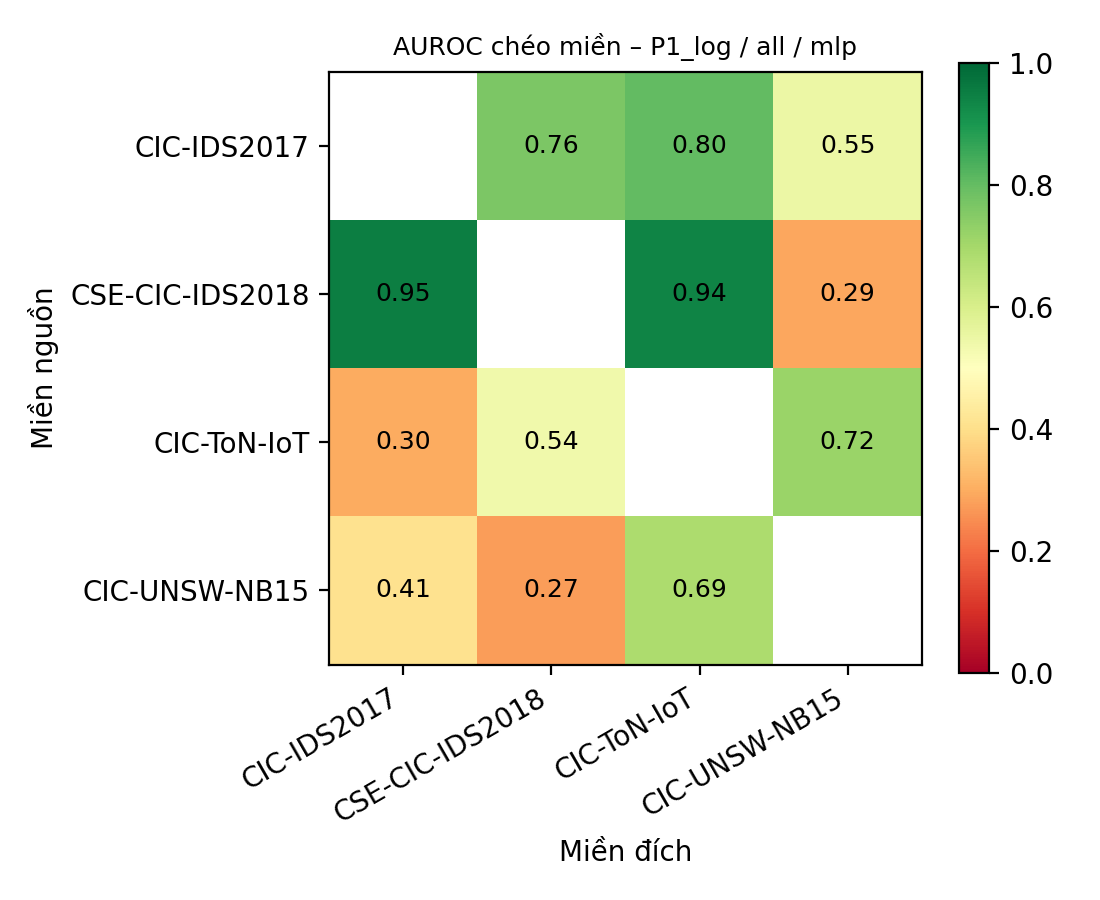

In [3]:
import sys
from google.colab import drive
drive.mount("/content/drive")
sys.path.insert(0, "/content/drive/MyDrive/TADP_Q1/code")
from tadp.config import get_config
from tadp.summary import summarize
from IPython.display import Image, display
B = "/content/drive/MyDrive/TADP_Q1"
DOMAINS_CIC = {"CIC-IDS2017": ["2017"], "CSE-CIC-IDS2018": ["2018"], "CIC-ToN-IoT": ["ton"], "CIC-UNSW-NB15": ["unsw"]}
cfg = get_config(RAW_DIR=f"{B}/raw_cic", CACHE_DIR=f"{B}/cache_cic", RESULT_DIR=f"{B}/results/v3_cic_theo_dot",
                 DOMAINS=DOMAINS_CIC, SPLIT_MODE="episode")
summarize(cfg)
display(Image(f"{cfg['RESULT_DIR']}/phase1_auroc_heatmap.png"))